# Conditional GAN (CGAN) - Skin Disease Image Dataset
Run on Colab with `Runtime > Change runtime type > T4 GPU`. Run cells top to bottom.
Keras 3 compatible (TensorFlow backend).

In [ ]:
!pip install -q kagglehub

import os
import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt

print("TF:", tf.__version__, "| Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("GPU:", tf.config.list_physical_devices('GPU'))

TF: 2.21.0 | Keras: 3.13.2 | backend: tensorflow
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Download dataset

In [ ]:
import kagglehub
path = kagglehub.dataset_download("riyaelizashaju/skin-disease-classification-image-dataset")
print("Path to dataset files:", path)

100%|██████████| 169M/169M [00:11<00:00, 15.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/riyaelizashaju/skin-disease-classification-image-dataset/versions/1


## Config

In [ ]:
DATASET_DIR = os.path.join(path, "Split_smol", "train")
IMG_SIZE = 64
CHANNELS = 3
BATCH_SIZE = 64
LATENT_DIM = 128
EPOCHS = 200
LEARNING_RATE = 2e-4
SAMPLE_EVERY = 5
OUTPUT_DIR = "/content/cgan_outputs" if os.path.isdir("/content") else "./cgan_outputs"
SEED = 42

os.makedirs(os.path.join(OUTPUT_DIR, "checkpoints"), exist_ok=True)

## Data pipeline

In [ ]:
def build_datasets():
    raw_ds = keras.utils.image_dataset_from_directory(
        DATASET_DIR,
        label_mode="categorical",
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=SEED,
    )
    class_names = raw_ds.class_names
    num_classes = len(class_names)
    print(f"Found {num_classes} classes: {class_names}")

    def preprocess(images, labels):
        images = tf.cast(images, tf.float32)
        images = (images - 127.5) / 127.5  # -> [-1, 1]
        return images, tf.cast(labels, tf.float32)

    ds = raw_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    return ds, num_classes, class_names


dataset, NUM_CLASSES, CLASS_NAMES = build_datasets()

Found 697 files belonging to 9 classes.
Found 9 classes: ['Actinic keratosis', 'Atopic Dermatitis', 'Benign keratosis', 'Dermatofibroma', 'Melanocytic nevus', 'Melanoma', 'Squamous cell carcinoma', 'Tinea Ringworm Candidiasis', 'Vascular lesion']


## Generator

In [ ]:
def build_generator(latent_dim, num_classes, img_size, channels):
    start_size = img_size // 16
    assert start_size * 16 == img_size, "IMG_SIZE must be divisible by 16"

    noise_input = keras.Input(shape=(latent_dim,), name="noise")
    label_input = keras.Input(shape=(num_classes,), name="label")

    x = layers.Concatenate()([noise_input, label_input])
    x = layers.Dense(start_size * start_size * 256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Reshape((start_size, start_size, 256))(x)

    for filters in [256, 128, 64, 32]:
        x = layers.Conv2DTranspose(filters, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(0.2)(x)

    out = layers.Conv2D(channels, kernel_size=5, padding="same", activation="tanh", name="gen_output")(x)
    return keras.Model([noise_input, label_input], out, name="generator")


generator = build_generator(LATENT_DIM, NUM_CLASSES, IMG_SIZE, CHANNELS)
generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noise (InputLayer)  │ (None, 128)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label (InputLayer)  │ (None, 9)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 137)       │          0 │ noise[0][0],      │
│ (Concatenate)       │                   │            │ label[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4096)      │    561,152 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 4096)      │     16,384 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 4096)      │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 4, 4, 256) │          0 │ leaky_re_lu[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 8, 8, 256) │  1,048,576 │ reshape[0][0]     │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 256) │      1,024 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 8, 8, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 16, 16,    │    524,288 │ leaky_re_lu_1[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 32, 32,    │    131,072 │ leaky_re_lu_2[0]… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_3  │ (None, 64, 64,    │     32,768 │ leaky_re_lu_3[0]… │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 32)               │            │                 

 Total params: 2,318,563 (8.84 MB)

 Trainable params: 2,309,411 (8.81 MB)

 Non-trainable params: 9,152 (35.75 KB)

## Discriminator

In [ ]:
def build_discriminator(num_classes, img_size, channels):
    image_input = keras.Input(shape=(img_size, img_size, channels), name="image")
    label_input = keras.Input(shape=(num_classes,), name="label")

    label_channels = layers.Dense(img_size * img_size)(label_input)
    label_channels = layers.Reshape((img_size, img_size, 1))(label_channels)

    x = layers.Concatenate()([image_input, label_channels])
    for filters in [64, 128, 256, 512]:
        x = layers.Conv2D(filters, kernel_size=4, strides=2, padding="same")(x)
        x = layers.LeakyReLU(0.2)(x)
        x = layers.Dropout(0.3)(x)

    x = layers.Flatten()(x)
    out = layers.Dense(1, name="disc_output")(x)  # raw logit
    return keras.Model([image_input, label_input], out, name="discriminator")


discriminator = build_discriminator(NUM_CLASSES, IMG_SIZE, CHANNELS)
discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None, 9)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4096)      │     40,960 │ label[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image (InputLayer)  │ (None, 64, 64, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 64, 64, 1) │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64, 64, 4) │          0 │ image[0][0],      │
│ (Concatenate)       │                   │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │      4,160 │ concatenate_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_5       │ (None, 32, 32,    │          0 │ conv2d[0][0]      │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32, 32,    │          0 │ leaky_re_lu_5[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │    131,200 │ dropout[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_6       │ (None, 16, 16,    │          0 │ conv2d_1[0][0]    │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 16, 16,    │          0 │ leaky_re_lu_6[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 8, 8, 256) │    524,544 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_7       │ (None, 8, 8, 256) │          0 │ conv2d_2[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 8, 8, 256) │          0 │ leaky_re_lu_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 4, 4, 512) │  2,097,664 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_8       │ (None, 4, 4, 512) │          0 │ conv2d_3[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 4, 4, 512) │          0 │ leaky_re_lu_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8192)      │          0 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_output (Dense) │ (None, 1)         │      8,193 │ flatten[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,806,721 (10.71 MB)

 Trainable params: 2,806,721 (10.71 MB)

 Non-trainable params: 0 (0.00 B)

## ConditionalGAN (class + `train_step` MUST stay in this one cell)

In [ ]:
class ConditionalGAN(keras.Model):
    def __init__(self, discriminator, generator, latent_dim, num_classes):
        super().__init__()
        self.discriminator = discriminator
        self.generator = generator
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.gen_loss_tracker = keras.metrics.Mean(name="generator_loss")
        self.disc_loss_tracker = keras.metrics.Mean(name="discriminator_loss")

    @property
    def metrics(self):
        return [self.gen_loss_tracker, self.disc_loss_tracker]

    def compile(self, d_optimizer, g_optimizer, loss_fn):
        super().compile()
        self.d_optimizer = d_optimizer
        self.g_optimizer = g_optimizer
        self.loss_fn = loss_fn

    def call(self, inputs, training=False):
        # Keras 3 needs a call() for build; real logic is in train_step.
        if isinstance(inputs, (list, tuple)) and len(inputs) == 2:
            return self.generator(list(inputs), training=training)
        return inputs

    def train_step(self, data):
        real_images, one_hot_labels = data
        batch_size = tf.shape(real_images)[0]

        # ---- Discriminator ----
        random_latent_vectors = tf.random.normal(shape=(batch_size, self.latent_dim))
        generated_images = self.generator([random_latent_vectors, one_hot_labels], training=True)

        combined_images = tf.concat([generated_images, real_images], axis=0)
        combined_labels = tf.concat([one_hot_labels, one_hot_labels], axis=0)

        # convention from the Keras example: generated = 1, real = 0
        labels = tf.concat([tf.ones((batch_size, 1)), tf.zeros((batch_size, 1))], axis=0)
        labels += 0.05 * tf.random.uniform(tf.shape(labels))

        with tf.GradientTape() as tape:
            predictions = self.discriminator([combined_images, combined_labels], training=True)
            d_loss = self.loss_fn(labels, predictions)
        grads = tape.gradient(d_loss, self.discriminator.trainable_weights)
        self.d_optimizer.apply_gradients(zip(grads, self.discriminator.trainable_weights))

        # ---- Generator ----
        random_latent_vectors = tf.random.normal(shape=(batch_size, self.latent_dim))
        misleading_labels = tf.zeros((batch_size, 1))  # pretend generated = real

        with tf.GradientTape() as tape:
            fake_images = self.generator([random_latent_vectors, one_hot_labels], training=True)
            predictions = self.discriminator([fake_images, one_hot_labels], training=True)
            g_loss = self.loss_fn(misleading_labels, predictions)
        grads = tape.gradient(g_loss, self.generator.trainable_weights)
        self.g_optimizer.apply_gradients(zip(grads, self.generator.trainable_weights))

        self.gen_loss_tracker.update_state(g_loss)
        self.disc_loss_tracker.update_state(d_loss)
        return {
            "g_loss": self.gen_loss_tracker.result(),
            "d_loss": self.disc_loss_tracker.result(),
        }


# sanity check: this must print True, otherwise Keras uses its default train_step
print("train_step defined in class:", "train_step" in ConditionalGAN.__dict__)

train_step defined in class: True


## Sample-preview callback

In [ ]:
class GANMonitor(keras.callbacks.Callback):
    def __init__(self, num_classes, class_names, latent_dim, output_dir, every=5, samples_per_class=4):
        super().__init__()
        self.num_classes = num_classes
        self.class_names = class_names
        self.latent_dim = latent_dim
        self.output_dir = output_dir
        self.every = every
        self.samples_per_class = samples_per_class

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every != 0:
            return

        total = self.num_classes * self.samples_per_class
        noise = tf.random.normal(shape=(total, self.latent_dim))
        labels = tf.repeat(tf.eye(self.num_classes, dtype=tf.float32), self.samples_per_class, axis=0)

        generated = self.model.generator([noise, labels], training=False)
        generated = np.clip(generated.numpy() * 127.5 + 127.5, 0, 255).astype("uint8")

        grid = self._make_grid(generated, self.num_classes, self.samples_per_class)
        keras.utils.save_img(os.path.join(self.output_dir, f"epoch_{epoch + 1:04d}.png"), grid)

        plt.figure(figsize=(self.samples_per_class * 1.5, self.num_classes * 1.5))
        plt.imshow(grid)
        plt.axis("off")
        plt.title(f"Epoch {epoch + 1}")
        plt.show()

        self.model.generator.save_weights(
            os.path.join(self.output_dir, "checkpoints", f"generator_epoch_{epoch + 1:04d}.weights.h5")
        )

    @staticmethod
    def _make_grid(images, rows, cols):
        h, w, c = images.shape[1:]
        grid = np.zeros((rows * h, cols * w, c), dtype=images.dtype)
        for idx, img in enumerate(images):
            r, col = divmod(idx, cols)
            grid[r * h:(r + 1) * h, col * w:(col + 1) * w, :] = img
        return grid


monitor = GANMonitor(NUM_CLASSES, CLASS_NAMES, LATENT_DIM, OUTPUT_DIR, every=SAMPLE_EVERY)

## Compile & train

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - d_loss: 0.4680 - g_loss: 2.5524
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 199ms/step - d_loss: 0.3499 - g_loss: 3.9570
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 201ms/step - d_loss: 0.5319 - g_loss: 3.0812
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 210ms/step - d_loss: 0.3931 - g_loss: 2.2929
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - d_loss: 0.4371 - g_loss: 2.9809

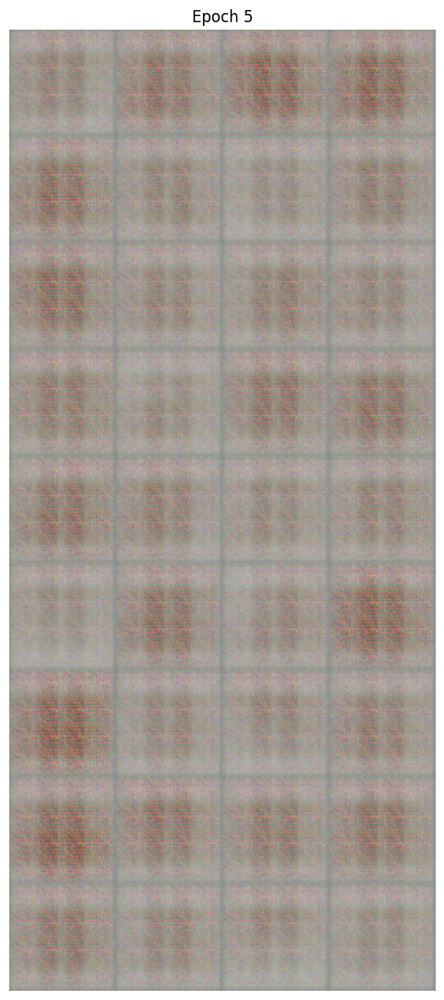

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 308ms/step - d_loss: 0.4376 - g_loss: 3.0027
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 209ms/step - d_loss: 0.4116 - g_loss: 2.0987
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 209ms/step - d_loss: 0.4534 - g_loss: 2.0617
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 216ms/step - d_loss: 0.4681 - g_loss: 1.7439
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 209ms/step - d_loss: 0.4761 - g_loss: 1.7901
Epoch 10/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - d_loss: 0.5574 - g_loss: 1.7317

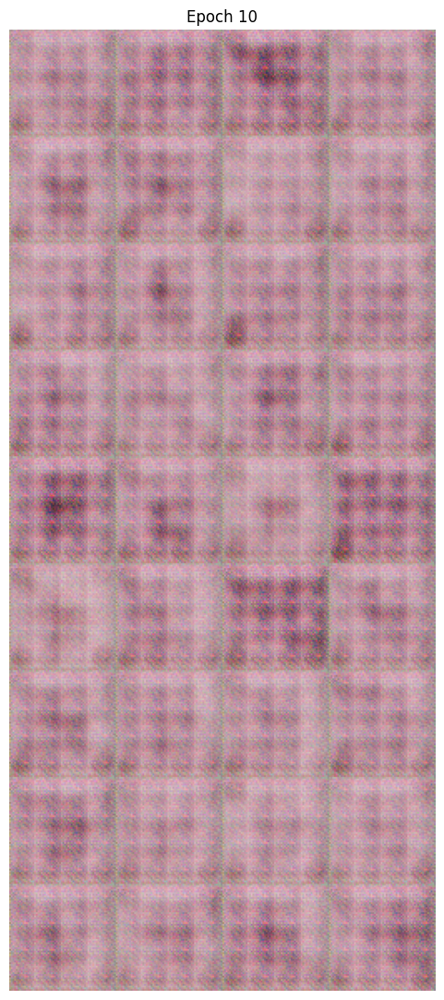

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step - d_loss: 0.5908 - g_loss: 1.7304
Epoch 11/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step - d_loss: 0.7370 - g_loss: 1.2697
Epoch 12/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step - d_loss: 0.6336 - g_loss: 0.9941
Epoch 13/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step - d_loss: 0.7114 - g_loss: 0.7214
Epoch 14/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 219ms/step - d_loss: 0.6664 - g_loss: 0.7281
Epoch 15/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - d_loss: 0.6567 - g_loss: 0.7174

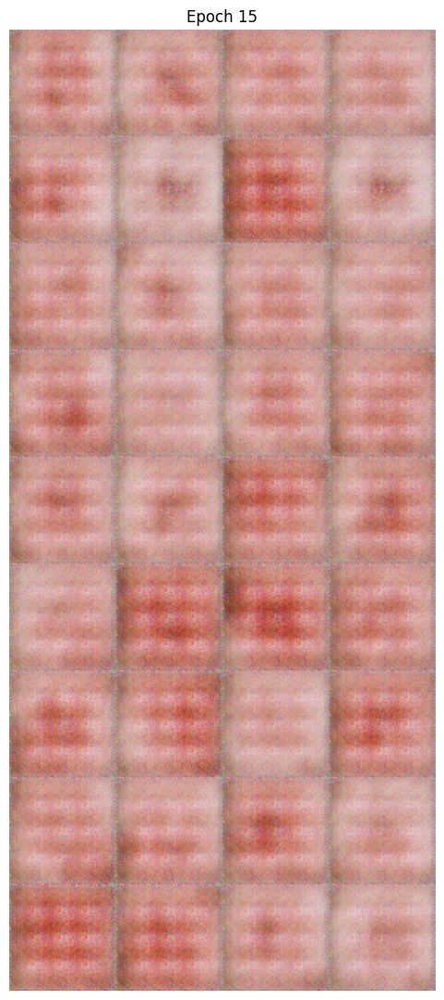

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 281ms/step - d_loss: 0.6632 - g_loss: 0.7096
Epoch 16/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step - d_loss: 0.6501 - g_loss: 0.7651
Epoch 17/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 227ms/step - d_loss: 0.6500 - g_loss: 0.7310
Epoch 18/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 227ms/step - d_loss: 0.6244 - g_loss: 0.7880
Epoch 19/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 233ms/step - d_loss: 0.6361 - g_loss: 0.8372
Epoch 20/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - d_loss: 0.6116 - g_loss: 0.8908

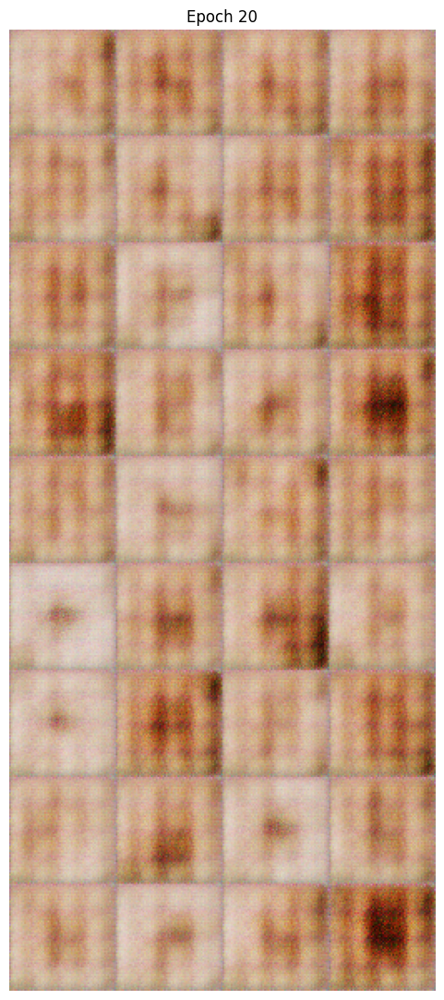

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 279ms/step - d_loss: 0.6179 - g_loss: 0.9047
Epoch 21/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 232ms/step - d_loss: 0.6275 - g_loss: 1.0107
Epoch 22/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 234ms/step - d_loss: 0.6199 - g_loss: 1.1395
Epoch 23/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 231ms/step - d_loss: 0.6536 - g_loss: 1.1532
Epoch 24/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 234ms/step - d_loss: 0.6699 - g_loss: 1.0883
Epoch 25/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - d_loss: 0.7054 - g_loss: 0.9364

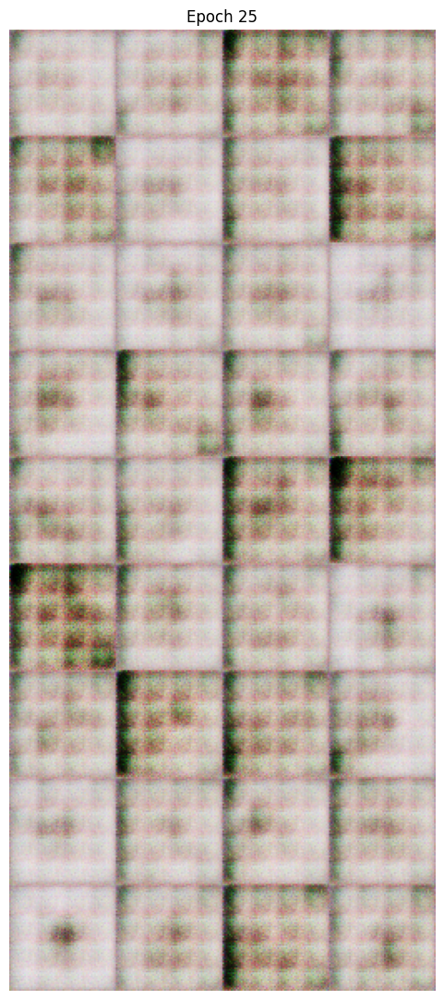

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 292ms/step - d_loss: 0.6833 - g_loss: 0.9891
Epoch 26/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step - d_loss: 0.6609 - g_loss: 0.9850
Epoch 27/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 249ms/step - d_loss: 0.6555 - g_loss: 1.0289
Epoch 28/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 240ms/step - d_loss: 0.6414 - g_loss: 0.8997
Epoch 29/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 238ms/step - d_loss: 0.6677 - g_loss: 0.9028
Epoch 30/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - d_loss: 0.6204 - g_loss: 0.8476

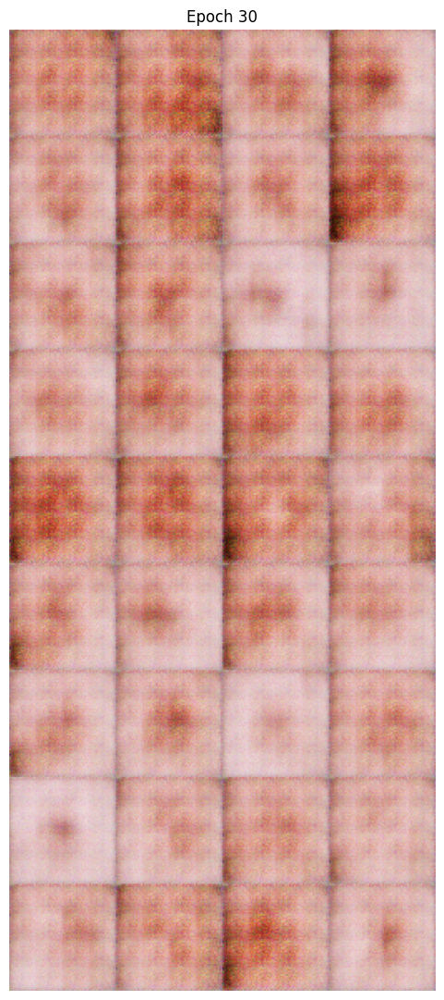

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 304ms/step - d_loss: 0.6224 - g_loss: 0.8509
Epoch 31/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 247ms/step - d_loss: 0.6340 - g_loss: 1.0272
Epoch 32/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 247ms/step - d_loss: 0.6129 - g_loss: 0.9306
Epoch 33/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 254ms/step - d_loss: 0.6537 - g_loss: 0.9548
Epoch 34/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 251ms/step - d_loss: 0.6592 - g_loss: 0.9253
Epoch 35/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step - d_loss: 0.5960 - g_loss: 0.9666

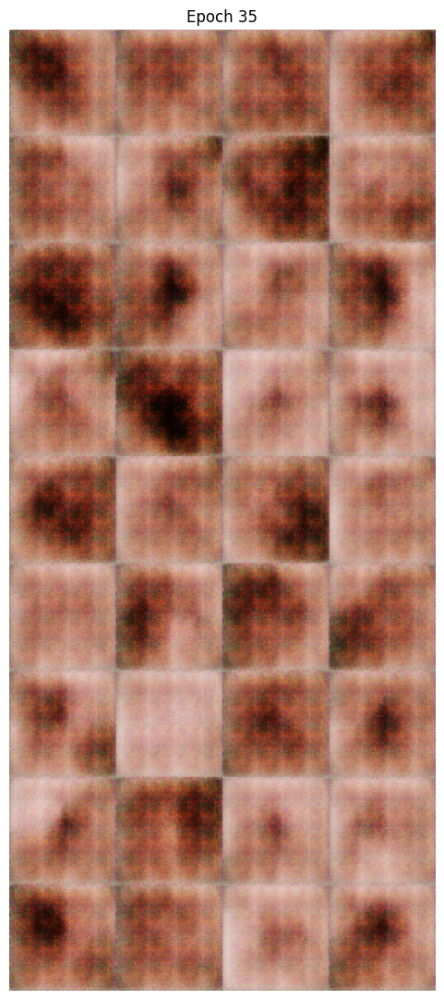

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 319ms/step - d_loss: 0.6119 - g_loss: 0.9516
Epoch 36/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 252ms/step - d_loss: 0.6144 - g_loss: 1.0140
Epoch 37/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 252ms/step - d_loss: 0.6172 - g_loss: 0.9373
Epoch 38/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 246ms/step - d_loss: 0.5967 - g_loss: 1.0302
Epoch 39/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step - d_loss: 0.6209 - g_loss: 1.1580
Epoch 40/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step - d_loss: 0.7948 - g_loss: 1.4936

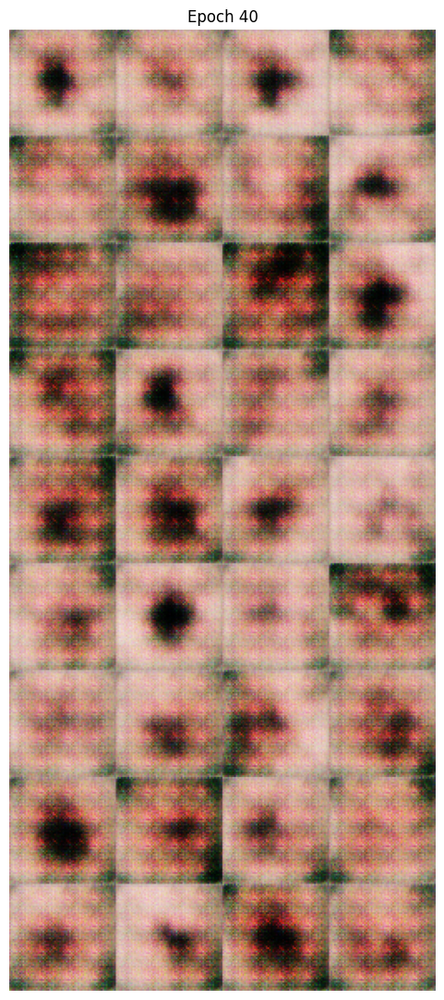

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 313ms/step - d_loss: 0.7589 - g_loss: 1.3683
Epoch 41/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 263ms/step - d_loss: 0.6604 - g_loss: 1.1113
Epoch 42/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 261ms/step - d_loss: 0.6704 - g_loss: 0.8486
Epoch 43/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 266ms/step - d_loss: 0.6478 - g_loss: 0.8714
Epoch 44/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 268ms/step - d_loss: 0.6414 - g_loss: 0.8725
Epoch 45/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - d_loss: 0.6405 - g_loss: 0.8951

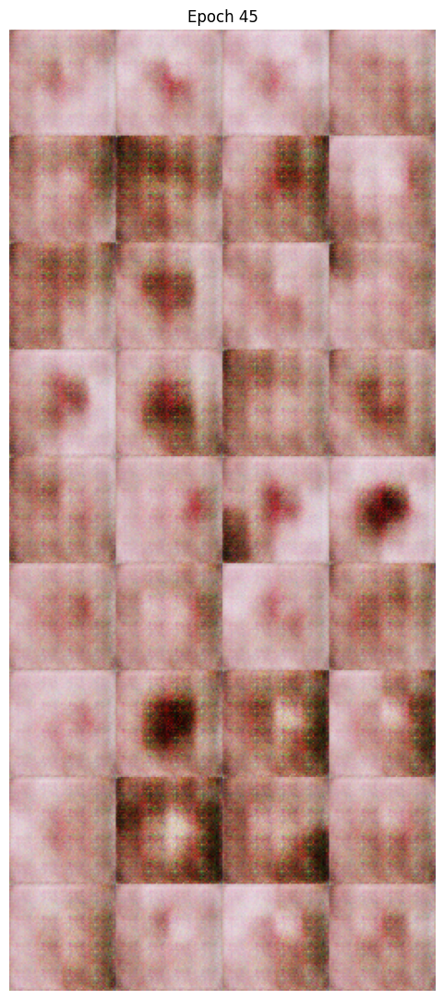

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 334ms/step - d_loss: 0.6372 - g_loss: 0.8918
Epoch 46/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 277ms/step - d_loss: 0.5998 - g_loss: 0.8835
Epoch 47/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 267ms/step - d_loss: 0.5752 - g_loss: 0.9800
Epoch 48/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 275ms/step - d_loss: 0.6336 - g_loss: 1.1785
Epoch 49/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 264ms/step - d_loss: 0.6190 - g_loss: 1.0037
Epoch 50/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - d_loss: 0.6180 - g_loss: 1.1485

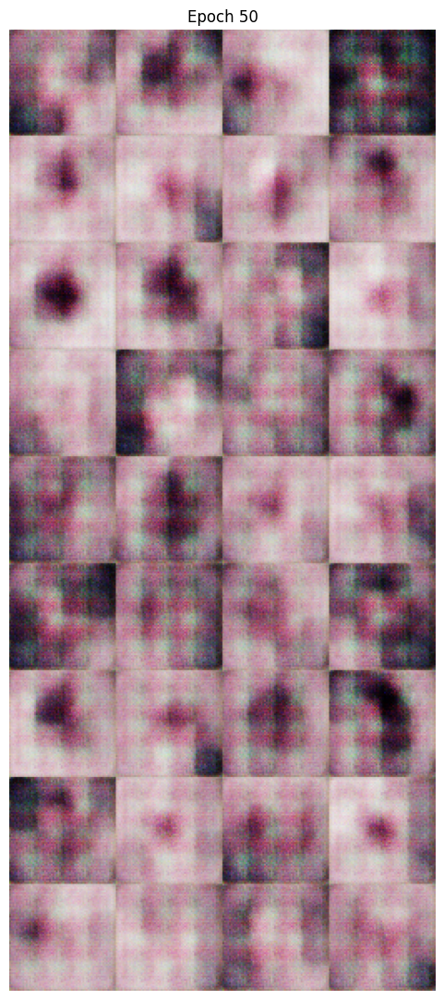

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 331ms/step - d_loss: 0.6445 - g_loss: 1.1834
Epoch 51/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 283ms/step - d_loss: 0.6458 - g_loss: 1.0229
Epoch 52/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 271ms/step - d_loss: 0.6041 - g_loss: 1.0123
Epoch 53/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 294ms/step - d_loss: 0.6054 - g_loss: 1.0018
Epoch 54/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 295ms/step - d_loss: 0.6432 - g_loss: 1.0248
Epoch 55/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - d_loss: 0.5913 - g_loss: 1.0704

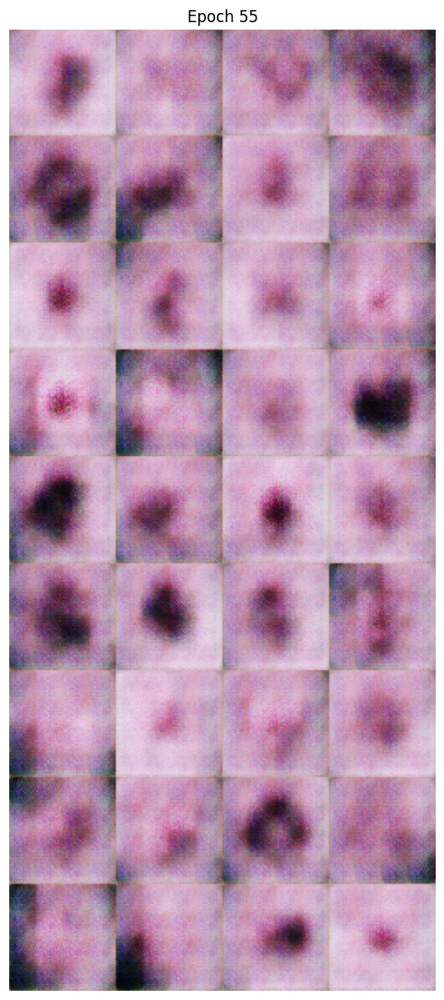

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 348ms/step - d_loss: 0.6087 - g_loss: 1.1443
Epoch 56/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 294ms/step - d_loss: 0.6256 - g_loss: 1.2011
Epoch 57/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 284ms/step - d_loss: 0.6086 - g_loss: 1.1051
Epoch 58/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 294ms/step - d_loss: 0.6026 - g_loss: 1.1868
Epoch 59/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 284ms/step - d_loss: 0.6484 - g_loss: 1.0080
Epoch 60/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - d_loss: 0.6066 - g_loss: 0.9898

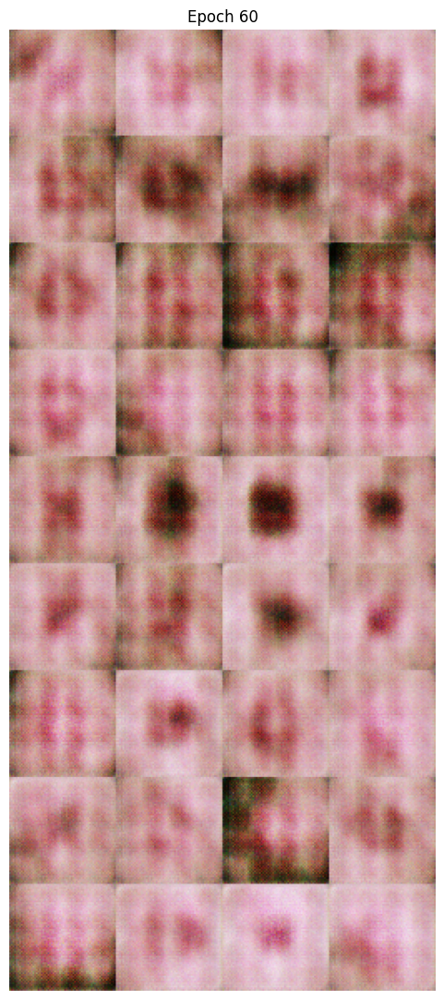

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 358ms/step - d_loss: 0.6146 - g_loss: 0.9805
Epoch 61/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 299ms/step - d_loss: 0.5546 - g_loss: 1.1263
Epoch 62/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 292ms/step - d_loss: 0.5306 - g_loss: 1.6459
Epoch 63/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 306ms/step - d_loss: 0.6157 - g_loss: 1.1924
Epoch 64/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 288ms/step - d_loss: 0.6299 - g_loss: 1.1293
Epoch 65/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - d_loss: 0.5103 - g_loss: 2.0491

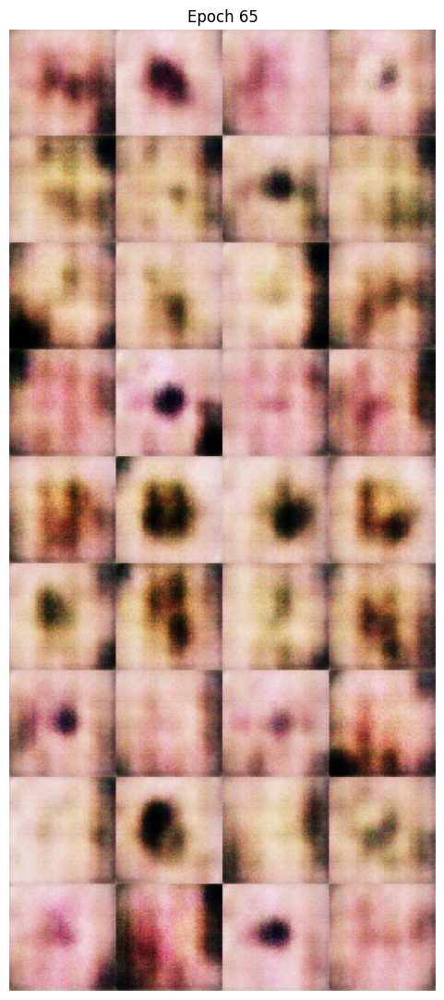

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 367ms/step - d_loss: 0.5665 - g_loss: 1.6553
Epoch 66/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 306ms/step - d_loss: 0.6282 - g_loss: 0.9740
Epoch 67/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 308ms/step - d_loss: 0.6916 - g_loss: 0.8230
Epoch 68/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 303ms/step - d_loss: 0.6201 - g_loss: 1.0502
Epoch 69/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 315ms/step - d_loss: 0.6830 - g_loss: 0.8663
Epoch 70/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - d_loss: 0.6606 - g_loss: 0.7785

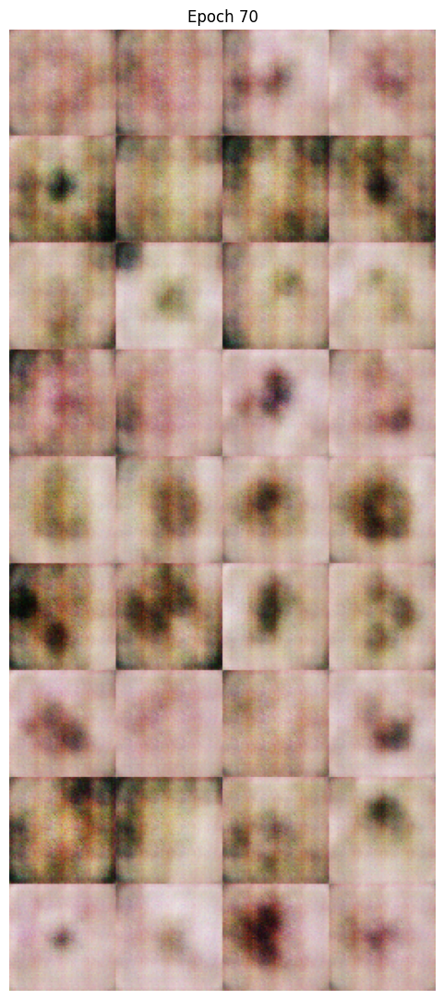

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 378ms/step - d_loss: 0.6381 - g_loss: 0.8097
Epoch 71/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 325ms/step - d_loss: 0.6392 - g_loss: 0.8645
Epoch 72/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 305ms/step - d_loss: 0.6590 - g_loss: 0.9483
Epoch 73/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 316ms/step - d_loss: 0.6630 - g_loss: 0.9288
Epoch 74/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 319ms/step - d_loss: 0.6444 - g_loss: 0.9394
Epoch 75/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - d_loss: 0.6648 - g_loss: 0.9032

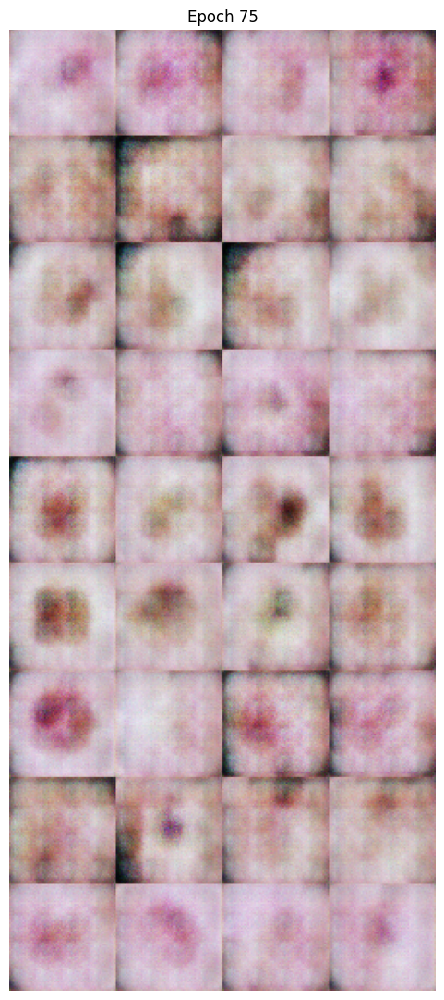

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 393ms/step - d_loss: 0.6502 - g_loss: 0.8809
Epoch 76/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 316ms/step - d_loss: 0.6798 - g_loss: 0.9003
Epoch 77/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 330ms/step - d_loss: 0.6363 - g_loss: 0.9612
Epoch 78/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 337ms/step - d_loss: 0.6205 - g_loss: 0.8571
Epoch 79/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 316ms/step - d_loss: 0.6728 - g_loss: 0.9465
Epoch 80/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - d_loss: 0.6532 - g_loss: 0.9336

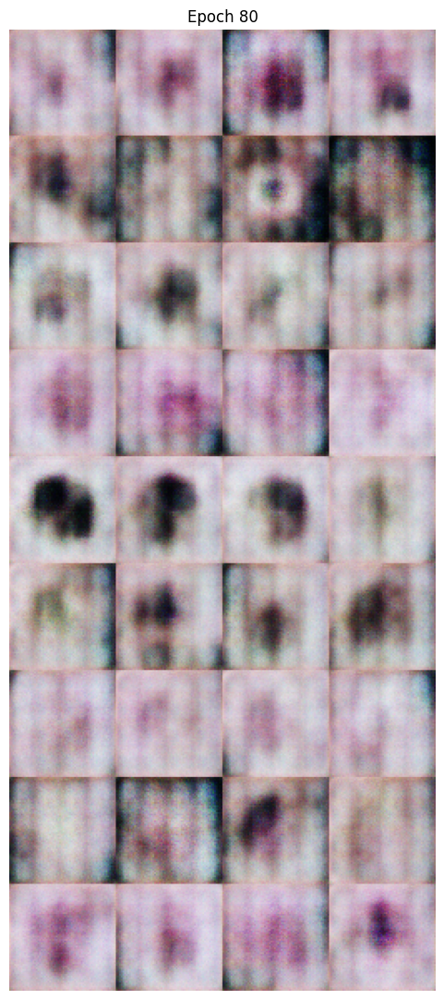

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 377ms/step - d_loss: 0.6881 - g_loss: 0.8893
Epoch 81/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 347ms/step - d_loss: 0.6209 - g_loss: 0.8552
Epoch 82/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 332ms/step - d_loss: 0.6831 - g_loss: 0.8813
Epoch 83/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 323ms/step - d_loss: 0.6510 - g_loss: 0.9356
Epoch 84/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 326ms/step - d_loss: 0.6521 - g_loss: 0.7967
Epoch 85/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step - d_loss: 0.6292 - g_loss: 0.8841

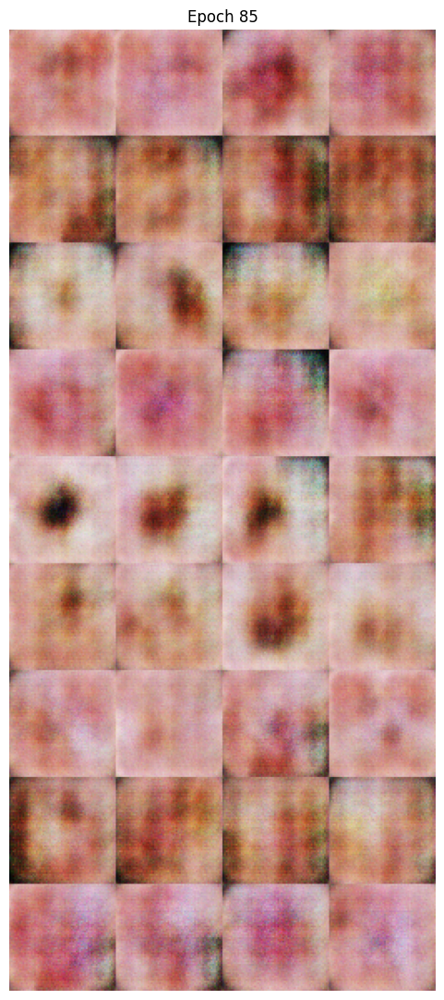

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 409ms/step - d_loss: 0.6346 - g_loss: 0.8932
Epoch 86/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 323ms/step - d_loss: 0.6814 - g_loss: 0.8917
Epoch 87/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 348ms/step - d_loss: 0.6449 - g_loss: 0.8528
Epoch 88/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 329ms/step - d_loss: 0.6551 - g_loss: 0.8334
Epoch 89/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 344ms/step - d_loss: 0.6562 - g_loss: 0.9219
Epoch 90/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step - d_loss: 0.6838 - g_loss: 0.8492

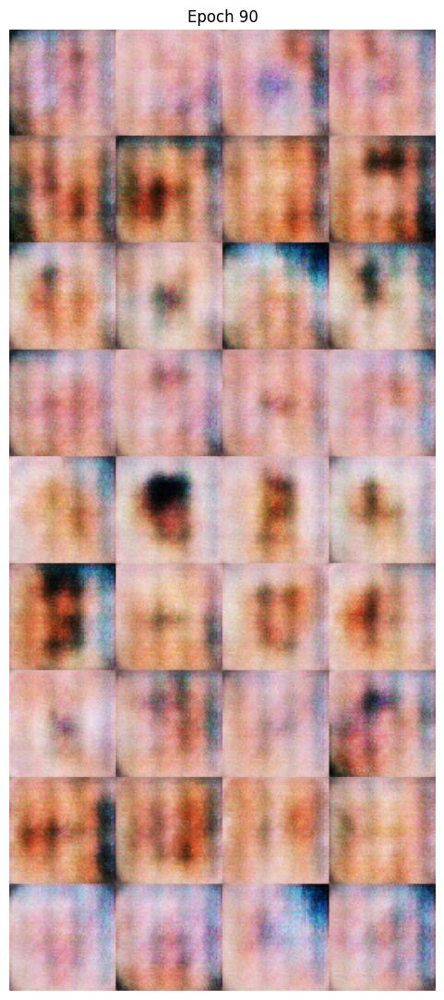

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 414ms/step - d_loss: 0.6672 - g_loss: 0.8446
Epoch 91/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 357ms/step - d_loss: 0.6477 - g_loss: 0.8418
Epoch 92/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 350ms/step - d_loss: 0.6545 - g_loss: 0.7964
Epoch 93/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 353ms/step - d_loss: 0.6479 - g_loss: 0.8762
Epoch 94/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 329ms/step - d_loss: 0.6593 - g_loss: 0.8428
Epoch 95/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - d_loss: 0.6355 - g_loss: 0.8936

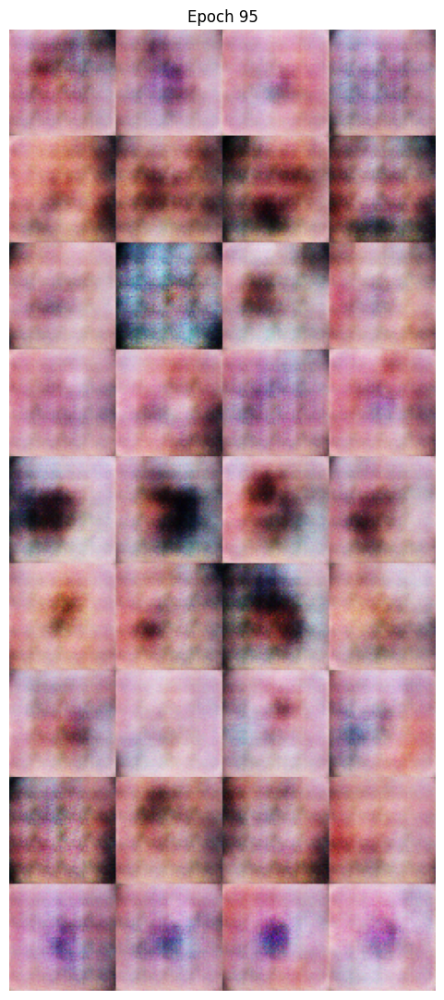

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 426ms/step - d_loss: 0.6463 - g_loss: 0.8818
Epoch 96/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 346ms/step - d_loss: 0.6433 - g_loss: 0.8642
Epoch 97/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 368ms/step - d_loss: 0.6549 - g_loss: 0.9569
Epoch 98/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 367ms/step - d_loss: 0.6559 - g_loss: 0.9463
Epoch 99/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 367ms/step - d_loss: 0.6417 - g_loss: 0.8984
Epoch 100/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - d_loss: 0.6397 - g_loss: 0.8656

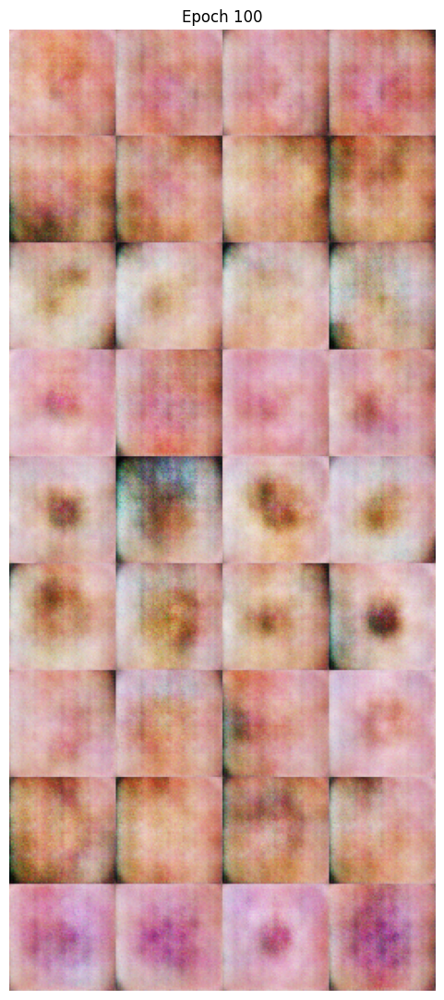

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 396ms/step - d_loss: 0.6407 - g_loss: 0.8552
Epoch 101/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 336ms/step - d_loss: 0.6313 - g_loss: 0.8982
Epoch 102/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 380ms/step - d_loss: 0.6477 - g_loss: 0.8741
Epoch 103/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 370ms/step - d_loss: 0.6489 - g_loss: 0.9121
Epoch 104/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 359ms/step - d_loss: 0.6274 - g_loss: 0.9169
Epoch 105/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step - d_loss: 0.6472 - g_loss: 0.8742

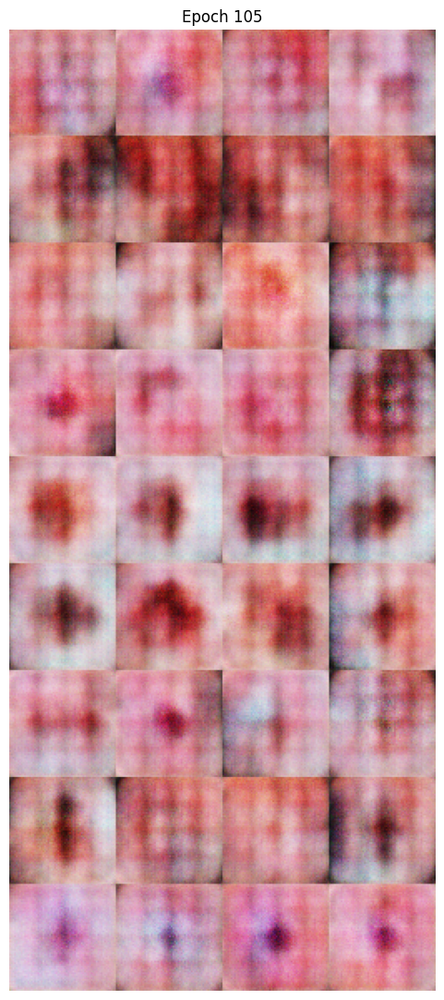

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 448ms/step - d_loss: 0.6370 - g_loss: 0.9228
Epoch 106/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 388ms/step - d_loss: 0.6372 - g_loss: 0.9194
Epoch 107/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 378ms/step - d_loss: 0.6329 - g_loss: 0.8942
Epoch 108/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 355ms/step - d_loss: 0.6484 - g_loss: 0.9021
Epoch 109/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 353ms/step - d_loss: 0.6276 - g_loss: 0.8868
Epoch 110/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - d_loss: 0.6323 - g_loss: 0.9791

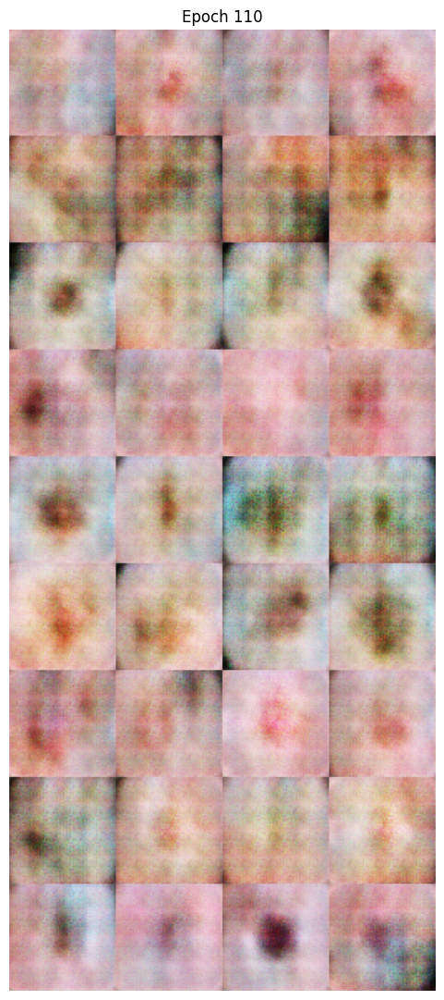

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 427ms/step - d_loss: 0.6419 - g_loss: 0.9609
Epoch 111/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 367ms/step - d_loss: 0.6461 - g_loss: 0.9358
Epoch 112/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 400ms/step - d_loss: 0.6330 - g_loss: 0.9072
Epoch 113/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 364ms/step - d_loss: 0.6282 - g_loss: 0.9133
Epoch 114/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 386ms/step - d_loss: 0.6423 - g_loss: 0.9438
Epoch 115/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step - d_loss: 0.6512 - g_loss: 0.8640

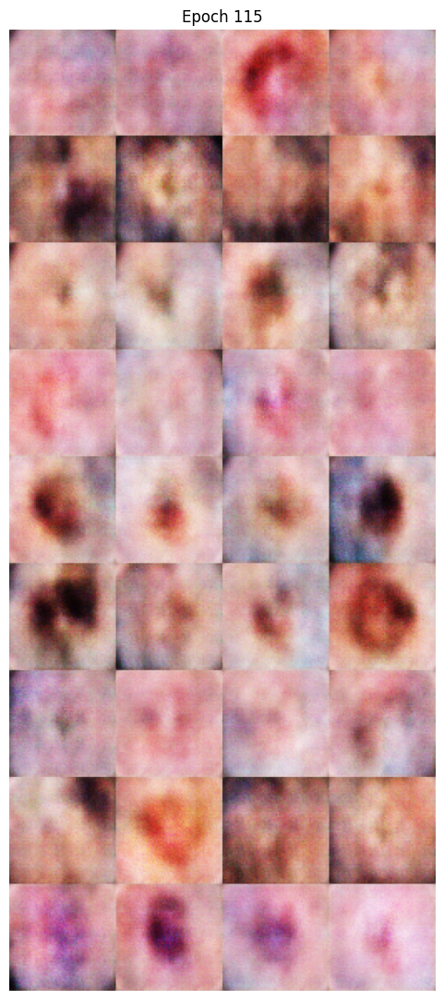

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 458ms/step - d_loss: 0.6403 - g_loss: 0.9046
Epoch 116/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 394ms/step - d_loss: 0.6426 - g_loss: 0.9048
Epoch 117/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 378ms/step - d_loss: 0.6501 - g_loss: 0.9209
Epoch 118/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 386ms/step - d_loss: 0.6358 - g_loss: 0.9552
Epoch 119/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 380ms/step - d_loss: 0.6393 - g_loss: 0.8899
Epoch 120/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - d_loss: 0.6476 - g_loss: 0.9027

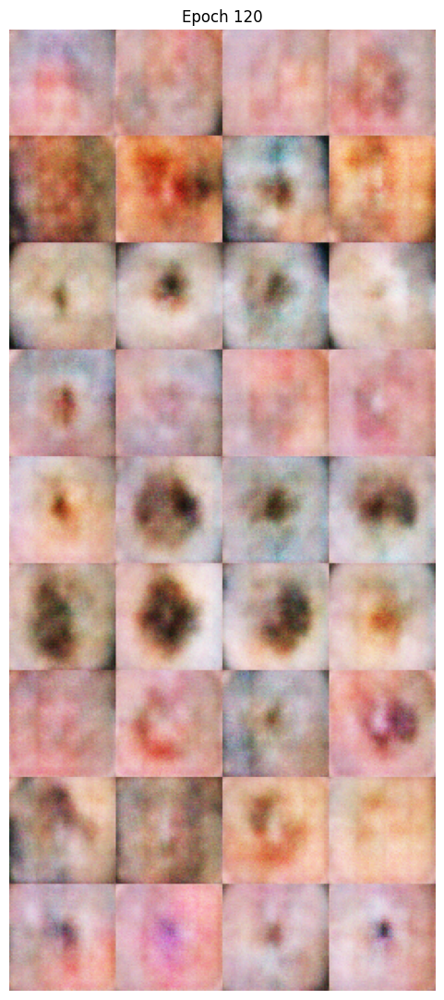

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 458ms/step - d_loss: 0.6480 - g_loss: 0.8762
Epoch 121/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 368ms/step - d_loss: 0.6461 - g_loss: 0.9019
Epoch 122/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 392ms/step - d_loss: 0.6495 - g_loss: 0.8869
Epoch 123/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 379ms/step - d_loss: 0.6493 - g_loss: 0.9223
Epoch 124/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 383ms/step - d_loss: 0.6465 - g_loss: 0.9205
Epoch 125/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - d_loss: 0.6509 - g_loss: 0.8661

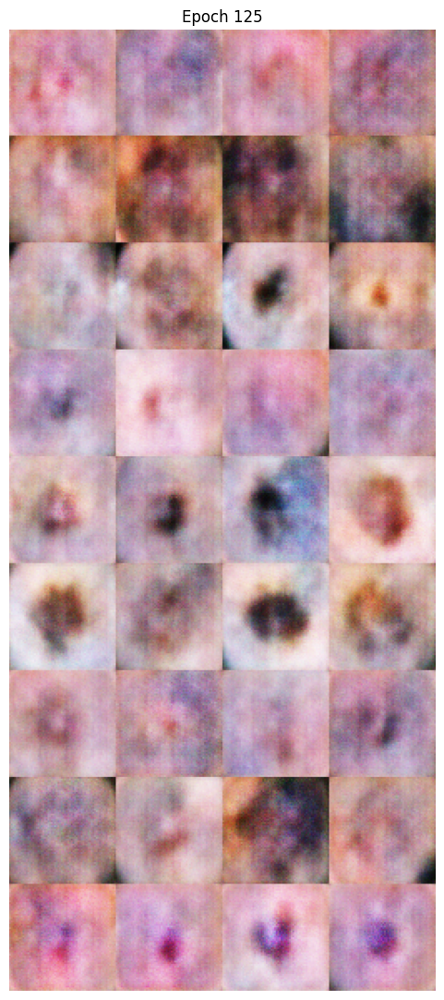

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 474ms/step - d_loss: 0.6523 - g_loss: 0.8583
Epoch 126/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 397ms/step - d_loss: 0.6482 - g_loss: 0.8756
Epoch 127/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 388ms/step - d_loss: 0.6449 - g_loss: 0.8933
Epoch 128/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 392ms/step - d_loss: 0.6485 - g_loss: 0.8401
Epoch 129/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 392ms/step - d_loss: 0.6520 - g_loss: 0.8877
Epoch 130/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - d_loss: 0.6466 - g_loss: 0.8851

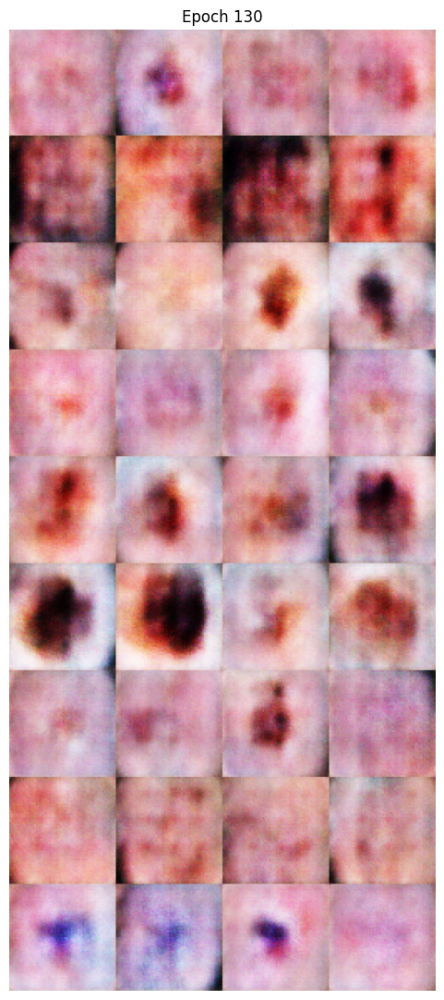

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 465ms/step - d_loss: 0.6548 - g_loss: 0.8625
Epoch 131/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 386ms/step - d_loss: 0.6444 - g_loss: 0.8818
Epoch 132/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 377ms/step - d_loss: 0.6534 - g_loss: 0.8783
Epoch 133/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 384ms/step - d_loss: 0.6488 - g_loss: 0.8715
Epoch 134/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 402ms/step - d_loss: 0.6457 - g_loss: 0.8566
Epoch 135/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step - d_loss: 0.6440 - g_loss: 0.8882

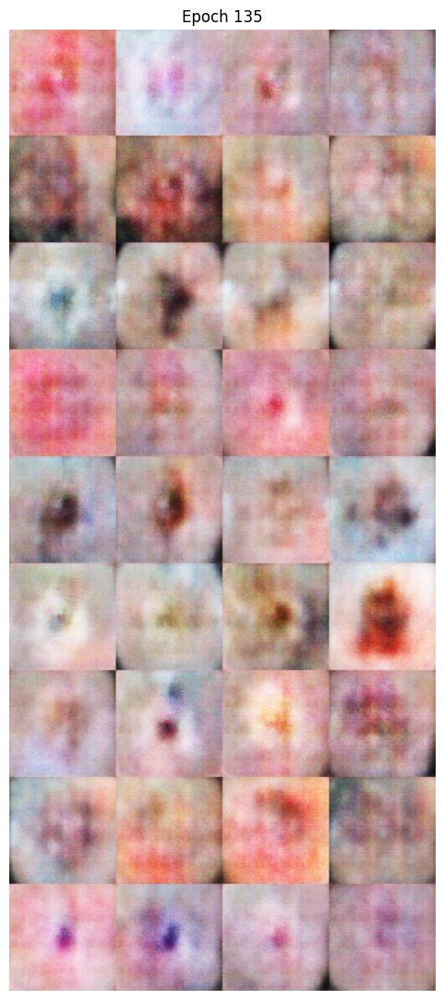

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 481ms/step - d_loss: 0.6468 - g_loss: 0.8931
Epoch 136/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 395ms/step - d_loss: 0.6404 - g_loss: 0.8973
Epoch 137/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 381ms/step - d_loss: 0.6508 - g_loss: 0.8804
Epoch 138/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 387ms/step - d_loss: 0.6434 - g_loss: 0.9385
Epoch 139/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 379ms/step - d_loss: 0.6497 - g_loss: 0.8586
Epoch 140/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - d_loss: 0.6241 - g_loss: 0.9347

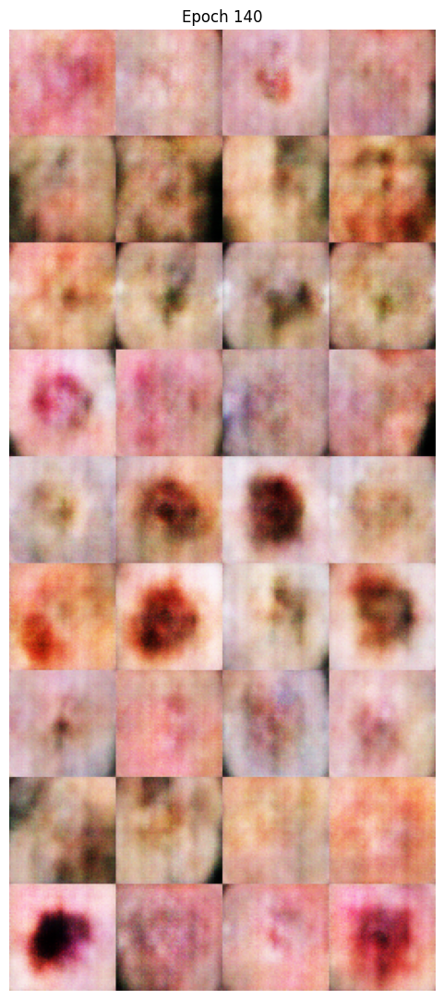

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 494ms/step - d_loss: 0.6355 - g_loss: 0.9415
Epoch 141/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 398ms/step - d_loss: 0.6434 - g_loss: 0.8846
Epoch 142/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 385ms/step - d_loss: 0.6229 - g_loss: 0.9771
Epoch 143/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 382ms/step - d_loss: 0.6525 - g_loss: 0.9293
Epoch 144/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 412ms/step - d_loss: 0.6327 - g_loss: 1.0000
Epoch 145/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - d_loss: 0.6194 - g_loss: 0.9364

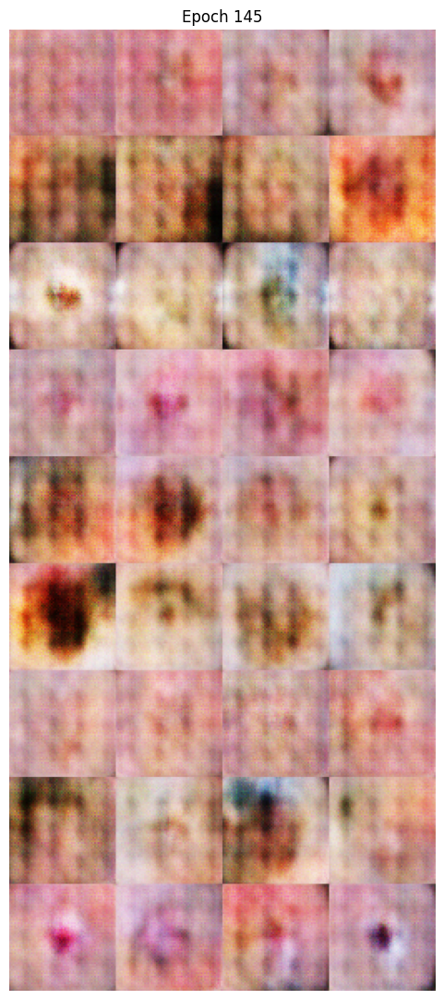

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 485ms/step - d_loss: 0.6135 - g_loss: 0.9602
Epoch 146/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 384ms/step - d_loss: 0.6063 - g_loss: 1.7687
Epoch 147/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 403ms/step - d_loss: 0.6391 - g_loss: 1.0007
Epoch 148/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 390ms/step - d_loss: 0.6444 - g_loss: 0.9446
Epoch 149/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 412ms/step - d_loss: 0.6427 - g_loss: 0.9646
Epoch 150/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - d_loss: 0.6484 - g_loss: 0.8577

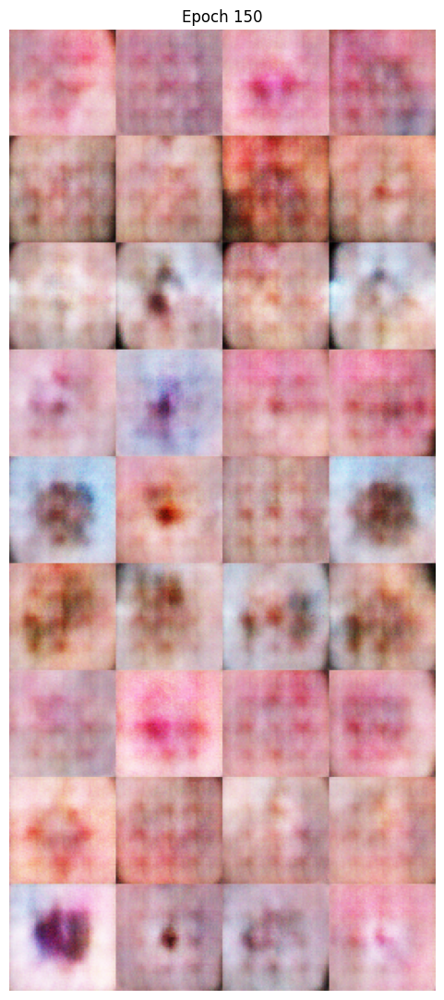

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 488ms/step - d_loss: 0.6380 - g_loss: 0.8796
Epoch 151/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 395ms/step - d_loss: 0.6155 - g_loss: 0.9251
Epoch 152/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 397ms/step - d_loss: 0.6391 - g_loss: 0.9306
Epoch 153/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 401ms/step - d_loss: 0.6205 - g_loss: 0.8865
Epoch 154/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 395ms/step - d_loss: 0.5724 - g_loss: 1.2659
Epoch 155/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - d_loss: 0.6643 - g_loss: 0.9344

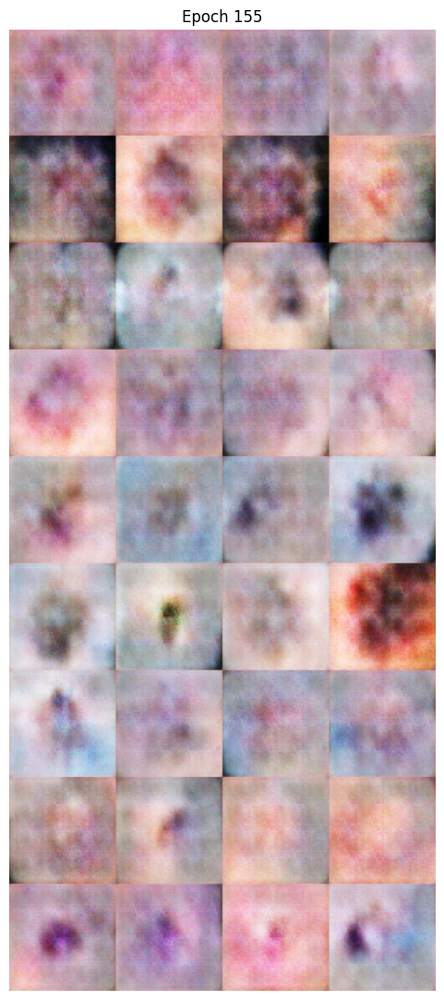

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 494ms/step - d_loss: 0.6736 - g_loss: 0.9062
Epoch 156/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 400ms/step - d_loss: 0.6244 - g_loss: 0.8955
Epoch 157/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 407ms/step - d_loss: 0.5998 - g_loss: 1.0122
Epoch 158/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 415ms/step - d_loss: 0.5661 - g_loss: 1.1235
Epoch 159/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 406ms/step - d_loss: 0.5963 - g_loss: 1.2801
Epoch 160/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step - d_loss: 0.6844 - g_loss: 0.9436

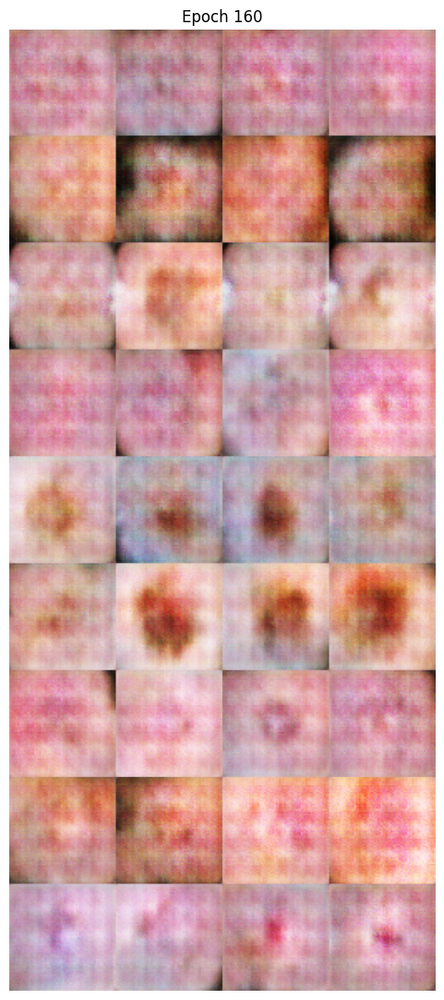

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 486ms/step - d_loss: 0.6677 - g_loss: 0.9498
Epoch 161/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 401ms/step - d_loss: 0.6434 - g_loss: 0.8917
Epoch 162/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 411ms/step - d_loss: 0.6439 - g_loss: 0.9473
Epoch 163/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 408ms/step - d_loss: 0.5878 - g_loss: 0.9411
Epoch 164/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 391ms/step - d_loss: 0.6176 - g_loss: 0.9752
Epoch 165/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - d_loss: 0.6797 - g_loss: 1.2804

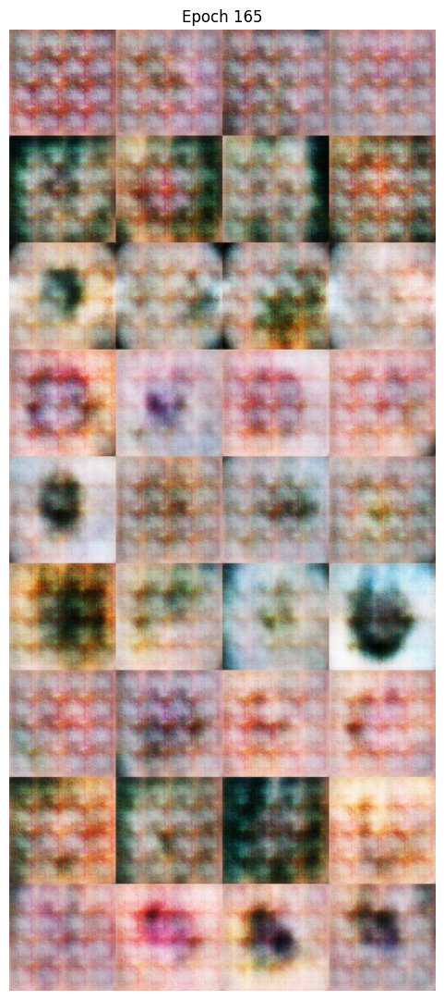

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 476ms/step - d_loss: 0.7113 - g_loss: 1.2444
Epoch 166/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 419ms/step - d_loss: 0.6891 - g_loss: 0.8548
Epoch 167/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 401ms/step - d_loss: 0.6568 - g_loss: 0.8137
Epoch 168/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 396ms/step - d_loss: 0.6511 - g_loss: 0.8671
Epoch 169/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 403ms/step - d_loss: 0.6484 - g_loss: 0.8581
Epoch 170/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - d_loss: 0.6412 - g_loss: 0.8378

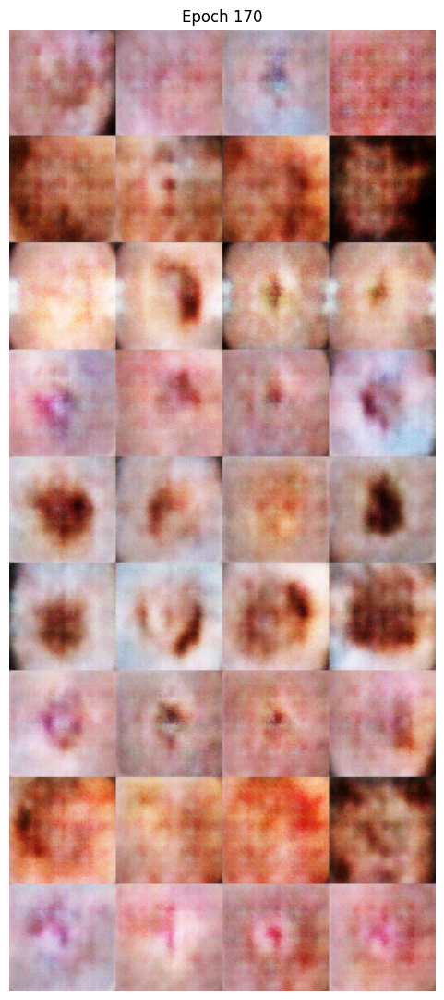

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 493ms/step - d_loss: 0.6404 - g_loss: 0.8504
Epoch 171/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 417ms/step - d_loss: 0.6309 - g_loss: 0.8597
Epoch 172/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 407ms/step - d_loss: 0.6361 - g_loss: 0.8559
Epoch 173/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 410ms/step - d_loss: 0.6320 - g_loss: 0.8988
Epoch 174/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 410ms/step - d_loss: 0.6330 - g_loss: 0.8817
Epoch 175/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step - d_loss: 0.6231 - g_loss: 0.8897

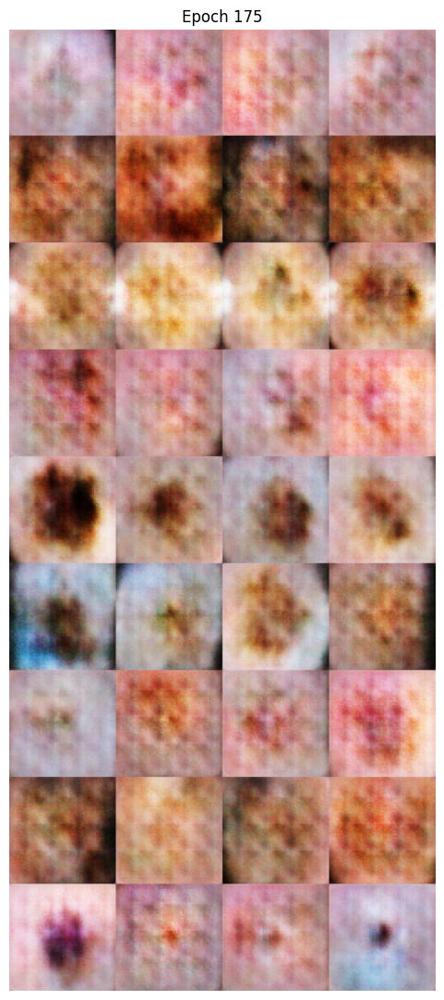

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 513ms/step - d_loss: 0.6275 - g_loss: 0.9137
Epoch 176/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 408ms/step - d_loss: 0.6107 - g_loss: 0.9024
Epoch 177/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 421ms/step - d_loss: 0.6143 - g_loss: 0.9019
Epoch 178/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 413ms/step - d_loss: 0.6116 - g_loss: 0.9483
Epoch 179/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 407ms/step - d_loss: 0.5769 - g_loss: 0.9773
Epoch 180/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - d_loss: 0.5293 - g_loss: 1.2426

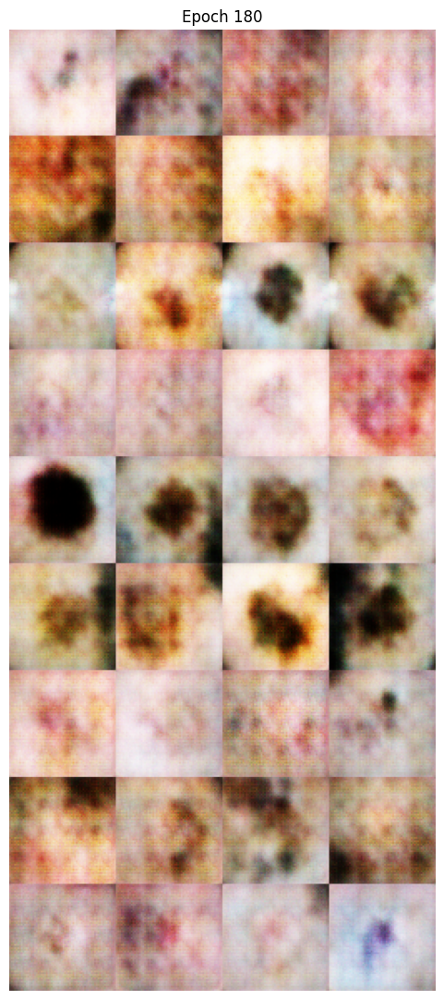

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 493ms/step - d_loss: 0.5649 - g_loss: 1.3511
Epoch 181/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 410ms/step - d_loss: 0.6269 - g_loss: 1.0438
Epoch 182/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 408ms/step - d_loss: 0.6341 - g_loss: 1.0082
Epoch 183/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 401ms/step - d_loss: 0.6068 - g_loss: 1.0567
Epoch 184/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 400ms/step - d_loss: 0.6222 - g_loss: 1.2047
Epoch 185/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step - d_loss: 0.6487 - g_loss: 1.0232

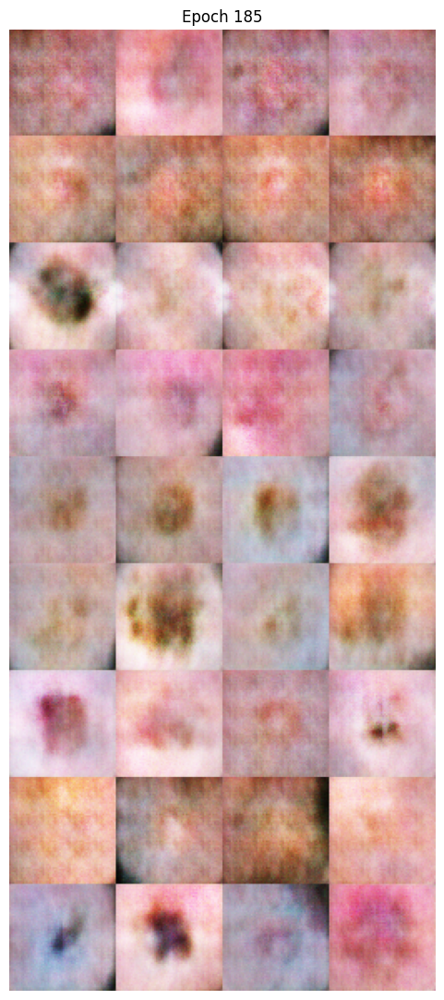

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 507ms/step - d_loss: 0.6402 - g_loss: 0.9830
Epoch 186/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 421ms/step - d_loss: 0.6029 - g_loss: 1.0099
Epoch 187/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 416ms/step - d_loss: 0.6104 - g_loss: 0.9521
Epoch 188/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 404ms/step - d_loss: 0.5789 - g_loss: 1.0728
Epoch 189/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 398ms/step - d_loss: 0.6031 - g_loss: 1.2321
Epoch 190/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - d_loss: 0.7241 - g_loss: 1.1041

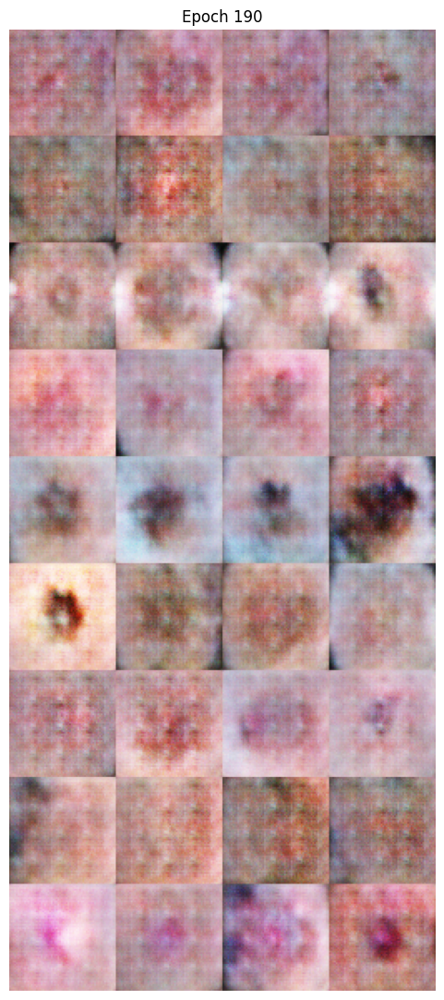

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 486ms/step - d_loss: 0.6833 - g_loss: 0.9954
Epoch 191/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 397ms/step - d_loss: 0.6613 - g_loss: 0.9110
Epoch 192/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 406ms/step - d_loss: 0.6180 - g_loss: 0.9351
Epoch 193/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 412ms/step - d_loss: 0.6285 - g_loss: 0.9340
Epoch 194/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 413ms/step - d_loss: 0.6145 - g_loss: 0.9317
Epoch 195/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - d_loss: 0.6244 - g_loss: 0.9667

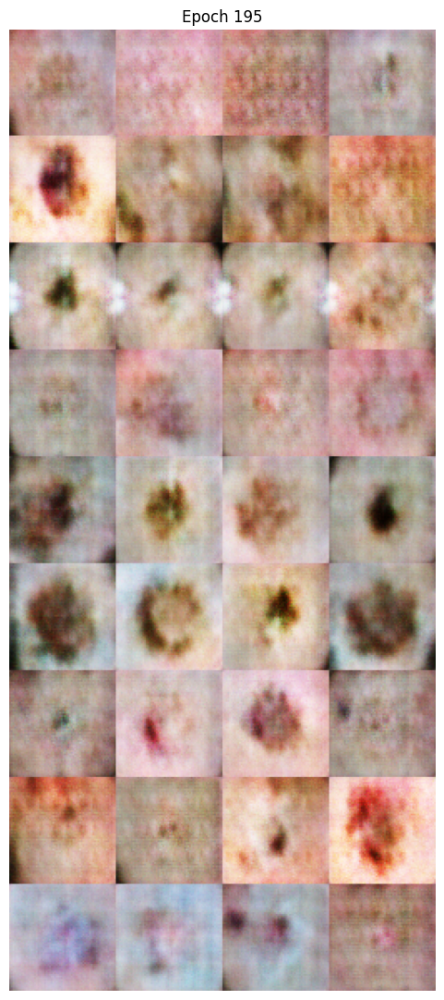

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 501ms/step - d_loss: 0.6261 - g_loss: 0.9449
Epoch 196/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 419ms/step - d_loss: 0.6022 - g_loss: 0.9458
Epoch 197/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 411ms/step - d_loss: 0.6208 - g_loss: 0.9343
Epoch 198/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 397ms/step - d_loss: 0.6024 - g_loss: 0.9753
Epoch 199/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 419ms/step - d_loss: 0.5734 - g_loss: 1.0510
Epoch 200/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - d_loss: 0.5117 - g_loss: 1.2600

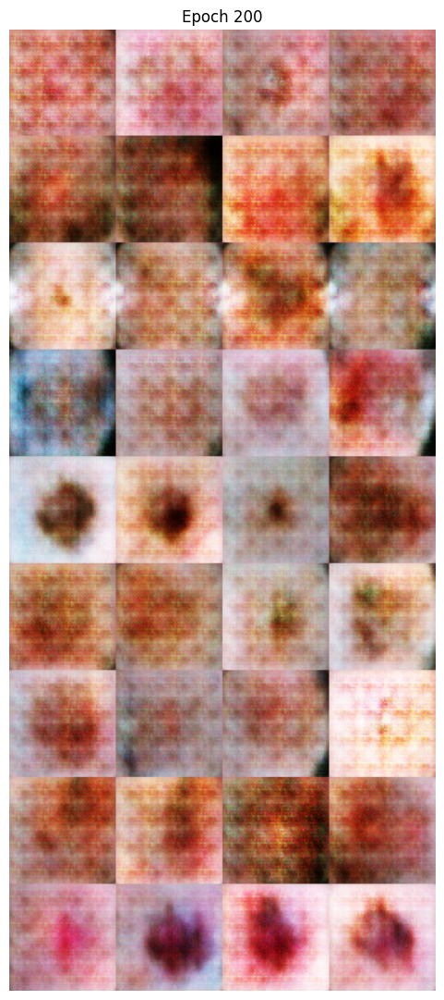

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 486ms/step - d_loss: 0.6002 - g_loss: 1.3601


In [ ]:
cgan = ConditionalGAN(discriminator=discriminator, generator=generator,
                      latent_dim=LATENT_DIM, num_classes=NUM_CLASSES)

cgan.compile(
    d_optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=0.5),
    g_optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=0.5),
    loss_fn=keras.losses.BinaryCrossentropy(from_logits=True),
)

history = cgan.fit(dataset, epochs=EPOCHS, callbacks=[monitor])

## Save final models

In [ ]:
generator.save(os.path.join(OUTPUT_DIR, "generator_final.keras"))
discriminator.save(os.path.join(OUTPUT_DIR, "discriminator_final.keras"))
print("Saved final models to", OUTPUT_DIR)

# from google.colab import files
# files.download(os.path.join(OUTPUT_DIR, "generator_final.keras"))

Saved final models to /content/cgan_outputs


## Generate images for a specific class

Generating for class: Benign keratosis


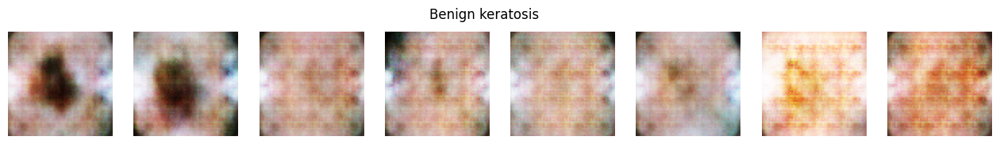

In [ ]:
def generate_for_class(generator, class_index, num_classes, latent_dim, n=8):
    noise = tf.random.normal(shape=(n, latent_dim))
    labels = np.zeros((n, num_classes), dtype="float32")
    labels[:, class_index] = 1.0
    imgs = generator([noise, tf.convert_to_tensor(labels)], training=False)
    return np.clip(imgs.numpy() * 127.5 + 127.5, 0, 255).astype("uint8")


class_idx = 2
print("Generating for class:", CLASS_NAMES[class_idx])
samples = generate_for_class(generator, class_idx, NUM_CLASSES, LATENT_DIM, n=8)

fig, axes = plt.subplots(1, 8, figsize=(16, 2))
for ax, img in zip(axes, samples):
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(CLASS_NAMES[class_idx])
plt.show()

In [ ]:
from google.colab import files
files.download("/content/cgan_outputs/generator_final.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(NUM_CLASSES, CLASS_NAMES)

9 ['Actinic keratosis', 'Atopic Dermatitis', 'Benign keratosis', 'Dermatofibroma', 'Melanocytic nevus', 'Melanoma', 'Squamous cell carcinoma', 'Tinea Ringworm Candidiasis', 'Vascular lesion']
